# 1. Introduction
# Opening the black box with Weights & Biases

This notebook asks two questions: **can someone rebuild this experiment, and how does the model produce a prediction?** Each run records its settings, data and results in Weights & Biases (W&B)

The data contain 4,000 intensive care unit (ICU) stays from [PhysioNet Challenge 2012, set A](https://physionet.org/content/challenge-2012/1.0.0/). The target is death before hospital discharge. Inputs summarise the first 48 h, so this is a prediction after that observation window, not at admission. Stays shorter than 48 h were excluded from the source cohort

**Session route:** follow sections 3 to 10. Section 8.3 is an optional extension, disabled in setup. Section 11 is an optional follow-up task

| Question | What students inspect | What is already covered elsewhere |
|---|---|---|
| Which experiment produced this result? | Runs, settings, versioned data and patient splits | New tracking focus |
| How sensitive is a score to randomness? | Refit models and compare paired scores on development splits | Notebook 03 section 8 uses a paired bootstrap of test patients instead |
| How does a forest calculate risk? | Tree probabilities, one decision path and averaging | Notebook 03 sections 5 to 6 introduce trees and forests |
| What explains this prediction? | SHapley Additive exPlanations (SHAP), with a sum check | Responsible Artificial Intelligence (RAI) notebook section 9 introduces explanation tools |
| Does a ranking imply useful prediction? | A forest trained on shuffled outcomes | Notebook 03 section 6.1 covers permutation importance |
| Can someone reproduce the final model? | Saved preprocessing and model, settings and data versions | New reproducibility focus |

Calibration, alert thresholds, subgroup audits and clinical decisions remain in notebooks 02, 03 and RAI. They are not repeated here. Those notebooks use different models or outcomes; their checks do not validate this model

**Data rule:** reserve the same test patients throughout. Use only the remaining development patients for exploration and tuning. Evaluate the final model on test once, in section 10

# 2. Setup

Select the `icu-survival` Python 3.11 environment from `environment.yml`. Save this notebook before running it so the logged code matches the saved file

The default route runs **online**: it needs a free W&B account and uploads the logged teaching data and artifacts to the selected project. Without an account or internet, set `WANDB_MODE` to `offline` in setup before starting a fresh kernel. Offline runs stay on this computer and skip the sweep and Registry

To link the final model in the Registry (section 10), paste the exact collection path into `REGISTRY_TARGET`. An empty path skips that step

In [1]:
# Setup: imports, reproducibility and shared helpers
from pathlib import Path
from importlib.metadata import version
from sklearn.base import clone
import hashlib
import json
import os
import sys
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
import joblib
from IPython.display import display, Markdown

import wandb
from wandb.plot import roc_curve as wandb_roc_curve
from wandb.plot import pr_curve as wandb_pr_curve
from wandb import Api as WandbApi

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import PartialDependenceDisplay
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, r2_score

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

WB_PROJECT = "ml-healthcare-intro"
DATA_ARTIFACT = "physionet2012-set-a"   # versioned dataset (section 4)
SPLIT_ARTIFACT = "icu-split-manifest"   # which patient is in train, validation or test (section 4)

# Random Forest settings used as the baseline in sections 5 to 8 (the sweep in section 9 tunes them)
RF_PARAMS = dict(n_estimators=300, max_depth=None, max_features="sqrt", min_samples_leaf=5)

# Choose the session route here, before starting runs
WANDB_MODE = os.environ.get("WANDB_MODE", "online")  # "offline" if you have no account or internet
RUN_SURROGATE = False  # optional surrogate exercise (section 8.3)
REGISTRY_TARGET = ""  # copy the exact path: wandb-registry-<registry name>/<collection name>
NOTEBOOK = Path("04_ICU_ML_W&B.ipynb")
OUTPUT_DIR = Path("tmp/wandb_outputs")  # ignored by git
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
os.environ["WANDB_MODE"] = WANDB_MODE
os.environ.setdefault("WANDB_SILENT", "true")
os.environ["WANDB_DIR"] = str(OUTPUT_DIR.resolve())
VERSIONS = {p: version(p) for p in ["numpy", "pandas", "scipy", "scikit-learn", "shap", "wandb", "joblib"]}
ENVIRONMENT = {"python": sys.version.split()[0], **VERSIONS}
INPUT_REFS = []
WB_ENTITY = None  # W&B account of this experiment, stored by the first run (section 4)
DATA_REF = None
DATA_SHA256 = None
SPLIT_SHA256 = None
print("Execution mode:", WANDB_MODE, "| Optional surrogate:", RUN_SURROGATE)
display(pd.Series(ENVIRONMENT, name="version").to_frame())
plt.rcParams.update({"figure.dpi": 110, "font.size": 11, "axes.spines.top": False, "axes.spines.right": False})

Execution mode: offline | Optional surrogate: False


,version
python,3.13.18
numpy,2.5.3
pandas,2.3.3
scipy,1.18.1
scikit-learn,1.9.1
shap,0.54.1
wandb,0.31.0
joblib,1.6.0


In [2]:
# --- Helpers reused by every run ---

def start_run(name, job_type, config=None, tags=None, group=None, inputs=True):
    """Record the environment and the exact inputs used by this run."""
    shared = {"environment": ENVIRONMENT, "optional_surrogate": RUN_SURROGATE, "split_seed": SEED, "model_seed": SEED,
              "dataset_sha256": DATA_SHA256, "main_split_sha256": SPLIT_SHA256}
    run = wandb.init(project=WB_PROJECT, name=name, job_type=job_type,
                     config={**shared, **(config or {})}, tags=tags or [], group=group,
                     reinit="finish_previous", save_code=True)
    run.log_code(root=".", include_fn=lambda p: Path(p).name == NOTEBOOK.name)
    if WANDB_MODE == "online" and inputs:
        for ref in INPUT_REFS:
            run.use_artifact(ref)  # pinned versions, never a moving :latest alias
    return run


def calibration_table(y_true, y_prob, n_bins=10):
    """Quantile bins of predicted risk vs observed death rate, and the Expected Calibration Error (ECE):
    the patient-weighted average gap between the two"""
    q = pd.qcut(y_prob, q=n_bins, duplicates="drop")
    if pd.isna(q).all():  # all predictions are equal: use one bin
        q = pd.Categorical(["all patients"] * len(y_prob))
    dfb = pd.DataFrame({"y_true": np.asarray(y_true), "y_prob": y_prob, "bin": q})
    agg = dfb.groupby("bin", observed=False).agg(
        mean_prob=("y_prob", "mean"), observed_rate=("y_true", "mean"), count=("y_true", "size")).reset_index()
    agg["bin"] = agg["bin"].astype(str)
    ece = float(np.sum(agg["count"] / agg["count"].sum() * np.abs(agg["observed_rate"] - agg["mean_prob"])))
    return agg, ece

def score(y_true, y_prob):
    """The four numbers every run logs: ranking (AUROC, AUPRC) and probability quality (Brier, ECE)"""
    return {"auc": roc_auc_score(y_true, y_prob), "pr": average_precision_score(y_true, y_prob),
            "brier": brier_score_loss(y_true, y_prob), "ece": calibration_table(y_true, y_prob)[1]}

def log_curves(y_true, y_prob, split):
    """Interactive ROC and PR curves logged to the open run"""
    probas_2d = np.stack([1.0 - y_prob, y_prob], axis=1)
    wandb.log({
        f"roc_curve_{split}": wandb_roc_curve(np.asarray(y_true), probas_2d),
        f"pr_curve_{split}": wandb_pr_curve(np.asarray(y_true), probas_2d),
    })


def log_top_bar(df, label, value, key, title, k=15):
    """W&B bar chart of the k rows with the largest absolute value"""
    top = df.reindex(df[value].abs().sort_values(ascending=False).index).head(k)
    wandb.log({key: wandb.plot.bar(wandb.Table(dataframe=top[[label, value]]), label, value, title=title)})

def log_fig(key, fig):
    """Log a matplotlib figure to W&B and also show it in the notebook"""
    wandb.log({key: wandb.Image(fig)})
    fig.tight_layout()
    plt.show()
    plt.close(fig)

def rf_shap(model, X_sample):
    """SHAP values of a tree ensemble for the 'died' class, as patients x features, plus the base value.
    For a scikit-learn Random Forest, SHAP values are in probability units"""
    explainer = shap.TreeExplainer(model, feature_perturbation="tree_path_dependent")
    sv = explainer.shap_values(X_sample)
    sv = np.asarray(sv[1]) if isinstance(sv, list) else np.asarray(sv)
    if sv.ndim == 3:
        sv = sv[..., 1]
    base = np.atleast_1d(explainer.expected_value)
    return sv, float(base[1] if base.size > 1 else base[0])

# 3. Weights & Biases in one minute

| Feature | Practical use here |
|---|---|
| Runs table | Compare the same validation metrics across models |
| Groups | Keep repeated experiments together |
| Tables and images | Inspect patients, tree paths and explanations |
| Artifacts and lineage | Record file versions and the runs that use or produce them |
| Sweeps | Try model settings against a chosen validation metric |
| Registry | Give a saved artifact version a shared name and alias |
| Code | Inspect the saved notebook used by a run |

An alias such as `staging` is a label, not evidence of approval or clinical readiness. Offline mode saves runs locally; it does not provide the online workspace, sweep or Registry

With five repetitions per randomness source, the core route creates 20 runs, plus 10 sweep trials online. The optional surrogate adds one run. Repeating cells creates further runs

In [3]:
if WANDB_MODE == "online":
    wandb.login()  # use the secure prompt; never paste a key into a notebook cell
else:
    print("Offline: runs stay under", OUTPUT_DIR.resolve())

Offline: runs stay under /home/claude/run04/tmp/wandb_outputs


# 4. Version the data and patient splits

A score needs a traceable source. This run records the raw data and a **split manifest**, a file listing each stay and its role: train, validation or test

The split uses 60% of stays for training, 20% for validation and 20% for the final test. Section 6 reshuffles only the first two groups. The test patients remain fixed

Missing inputs are filled using training medians. `recordid` identifies stays and is not a predictor. `Survival` and `Length_of_stay` describe later outcomes and are removed

The source uses `-1` for unknown values. Convert these codes to missing inputs before fitting the imputer; otherwise a severity score of -1 would be treated as a real measurement

**Names that appear in the outputs:** Simplified Acute Physiology Score I (`SAPS-I`) and Sequential Organ Failure Assessment (`SOFA`) summarise illness severity. Other shortened feature names follow the [source data dictionary](https://physionet.org/content/challenge-2012/1.0.0/)

| Feature family | Plain meaning |
|---|---|
| `GCS` | Glasgow Coma Scale, a responsiveness score |
| `BUN` | Blood urea nitrogen, a kidney-related blood test |
| `ALP` | Alkaline phosphatase, a blood enzyme measurement |
| `WBC`, `HCT` | White blood cell count and haematocrit |
| `HR`, `NISysABP` | Heart rate and non-invasive systolic blood pressure |
| `PaO2` | Arterial oxygen partial pressure |
| `MechVent`, `Temp` | Mechanical ventilation and temperature |

`first`, `last`, `highest`, `lowest` and `median` name summaries of recorded measurements. The plots retain the source values so their inputs match the model; these names describe measurements, not diagnoses

In [4]:
PATH = "PhysionetChallenge2012-set-a.csv.gz"
if not os.path.exists(PATH):
    raise FileNotFoundError(f"Data file not found at '{PATH}'. Place it next to this notebook")
ICU = pd.read_csv(PATH, compression="gzip")

TARGET = "In-hospital_death"
ID_COL = "recordid"
LEAKAGE_COLS = ["Survival", "Length_of_stay"]  # known only at the end of the stay
assert ICU[ID_COL].notna().all() and ICU[ID_COL].is_unique, "Each ICU stay needs one unique ID"
assert ICU[TARGET].notna().all() and ICU[TARGET].isin([0, 1]).all(), "Check outcome labels"
ICU[TARGET] = ICU[TARGET].astype(int)
DATA_SHA256 = hashlib.sha256(Path(PATH).read_bytes()).hexdigest()
run = start_run("01-data-and-splits", "data", config={"dataset_sha256": DATA_SHA256}, inputs=False)
WB_ENTITY = run.entity  # reused in section 10, so the sweep is read from the same account

X = ICU.drop(columns=[c for c in [TARGET, ID_COL, *LEAKAGE_COLS] if c in ICU.columns])
# PhysioNet uses -1 for missing or unknown values; valid source inputs are nonnegative
source_missing = int(X.eq(-1).sum().sum())
print(f"Predictors contain {source_missing} missing-value codes (-1); preprocessing converts these to NaN")
y = ICU[TARGET]
cat_cols = [c for c in X.columns if X[c].dtype == "object"]
num_cols = [c for c in X.columns if c not in cat_cols]

# Basic facts, logged to the run summary
miss = X.replace(-1, np.nan).isna().mean().sort_values(ascending=False)
wandb.log({"dataset_rows": len(ICU), "n_features": X.shape[1], "positive_rate": float(y.mean())})
log_top_bar(miss.rename("missing_fraction").rename_axis("column").reset_index(),
            "column", "missing_fraction", "missingness_top15_chart", "Fraction missing (top 15)")

# Version the raw file
data_at = wandb.Artifact(DATA_ARTIFACT, type="dataset",
                         description="PhysioNet Challenge 2012 set A, one row per ICU stay (first 48 h summaries)",
                         metadata={"rows": len(ICU), "positive_rate": float(y.mean()), "target": TARGET})
data_at.add_file(PATH)
logged_data = run.log_artifact(data_at)

# Set aside test once. Later repetitions use only the development pool
idx_dev, idx_test = train_test_split(ICU.index, test_size=0.2, stratify=y, random_state=SEED)

def make_split(split_seed):
    """Split development 75/25, retaining the same held-out test patients."""
    itr, iva = train_test_split(idx_dev, test_size=0.25, stratify=y.loc[idx_dev], random_state=split_seed)
    assert set(itr).isdisjoint(idx_test) and set(iva).isdisjoint(idx_test)
    return itr, iva, idx_test

def make_preprocessor():
    columns = ColumnTransformer([
        ("num", SimpleImputer(strategy="median", keep_empty_features=True), num_cols),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent", keep_empty_features=True)),
                          ("oh", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat_cols),
    ], verbose_feature_names_out=False).set_output(transform="pandas")
    return Pipeline([
        ("source_missing", FunctionTransformer(pd.DataFrame.replace,
             kw_args={"to_replace": -1, "value": np.nan}, feature_names_out="one-to-one")),
        ("columns", columns),
    ])

def prepare(itr, iva):
    pre = make_preprocessor()
    return pre.fit_transform(X.loc[itr]), pre.transform(X.loc[iva])

def split_manifest(itr, iva, ite):
    return pd.concat([pd.DataFrame({ID_COL: ICU.loc[idx, ID_COL].values, "split": name})
                      for name, idx in [("train", itr), ("val", iva), ("test", ite)]], ignore_index=True)

idx_train, idx_val, idx_test = make_split(SEED)
preprocessor = make_preprocessor()
X_train_t = preprocessor.fit_transform(X.loc[idx_train])
X_val_t = preprocessor.transform(X.loc[idx_val])
y_train, y_val = y.loc[idx_train], y.loc[idx_val]
feat_names = list(X_train_t.columns)

# Version the split: anyone can rebuild the same train, validation and test patients
manifest = split_manifest(idx_train, idx_val, idx_test)
manifest_file = OUTPUT_DIR / f"split_manifest_seed{SEED}.csv"
manifest.to_csv(manifest_file, index=False)
SPLIT_SHA256 = hashlib.sha256(manifest_file.read_bytes()).hexdigest()
run.config.update({"main_split_sha256": SPLIT_SHA256}, allow_val_change=True)
split_at = wandb.Artifact(SPLIT_ARTIFACT, type="split", description="Patient-level 60/20/20 stratified split",
                          metadata={"seed": SEED, **manifest["split"].value_counts().to_dict()})
split_at.add_file(str(manifest_file))
logged_split = run.log_artifact(split_at)
if WANDB_MODE == "online":
    logged_data.wait()
    logged_split.wait()
    DATA_REF = logged_data.qualified_name
    INPUT_REFS = [DATA_REF, logged_split.qualified_name]
    print("Pinned input versions:", INPUT_REFS)
wandb.log({"train_rows": len(idx_train), "val_rows": len(idx_val), "test_rows": len(idx_test)})

print(f"Run URL: {run.url if WANDB_MODE == 'online' else 'offline'}")
print(f"{len(ICU)} stays, {X.shape[1]} features, death rate {y.mean():.3f}")
print(f"Train {len(idx_train)}, validation {len(idx_val)}, test {len(idx_test)}")
run.finish()

Predictors contain 334 missing-value codes (-1); preprocessing converts these to NaN
Run URL: offline
4000 stays, 116 features, death rate 0.139
Train 2400, validation 800, test 800


### Read the result

- Check the printed stay count, feature count, death rate and split sizes
- Online, inspect the data and split artifact versions. A new collection starts at `v0`; existing collections may have later versions
- Rerun without changing the files and compare versions. W&B uses content checksums to detect changes
- Inspect the Code tab. Save edits before rerunning so the stored notebook is current

> Save the data version and patient split with every experiment

# 5. Compare three tracked baselines

Train logistic regression (LR), a shallow decision tree (DT) and a random forest (RF) on the same patients. Each gets one W&B run and the same validation metrics. Coefficient interpretation and full tree diagrams are covered in RAI section 5.2 and notebook 03 section 5, so they are not repeated

| Logged metric | Meaning | Better direction |
|---|---|---|
| `val_auc` | Area under the receiver operating characteristic curve (AUROC): how well deaths rank above survivors | Higher; chance ranking is 0.5 |
| `val_pr` | Average precision, used here to summarise the precision-recall curve | Higher; compare with this validation set's death rate |
| `val_brier` | Mean squared error between predicted probability and outcome, 0 or 1 | Lower |
| `val_ece` | Expected calibration error (ECE): weighted average gap between predicted and observed rates in up to 10 equal-count bins | Lower; depends on the chosen bins |

The label **AUPRC** means area under the precision-recall curve. Here it refers to scikit-learn's average precision calculation, not trapezoidal area. The Brier score measures overall probability error; ECE is a coarse calibration check. Neither establishes clinical usefulness

In [5]:
def run_baseline(name, model, config, tags):
    """Fit one model, log validation metrics and curves, return the open run, the fitted model and its validation risks"""
    run = start_run(name, "baseline", config={**config, "seed": SEED}, tags=["baseline", *tags])
    model.fit(X_train_t, y_train)
    p_val = model.predict_proba(X_val_t)[:, 1]
    metrics = {f"val_{k}": v for k, v in score(y_val, p_val).items()}
    wandb.log(metrics)
    log_curves(y_val, p_val, "val")
    return run, model, p_val, metrics

results = {}

# Logistic regression uses standardised inputs
run, log_reg, _, results["logistic_regression"] = run_baseline(
    "02-baseline-logistic-regression",
    Pipeline([("scale", StandardScaler()), ("lr", LogisticRegression(max_iter=1000, solver="liblinear", random_state=SEED))]),
    {"model_type": "logistic_regression", "standard_scaling": True, "max_iter": 1000, "solver": "liblinear"}, ["logistic_regression"])
run.finish()

# Decision tree: a shallow reference model
run, dt, _, results["decision_tree"] = run_baseline(
    "02-baseline-decision-tree", DecisionTreeClassifier(max_depth=4, min_samples_leaf=20, random_state=SEED),
    {"model_type": "decision_tree", "max_depth": 4, "min_samples_leaf": 20}, ["decision_tree"])
run.finish()

# Random Forest: oob_score=True keeps the out-of-bag predictions used in sections 7 and 8
run, rf, p_val_rf, results["random_forest"] = run_baseline(
    "02-baseline-random-forest", RandomForestClassifier(**RF_PARAMS, oob_score=True, random_state=SEED, n_jobs=-1),
    {"model_type": "random_forest", **RF_PARAMS}, ["random_forest"])
imp_df = pd.DataFrame({"feature": feat_names, "impurity_importance": rf.feature_importances_})
log_top_bar(imp_df, "feature", "impurity_importance", "rf_impurity_importance_chart", "RF impurity importance (top 15)")
run.finish()

baseline_df = pd.DataFrame(results).T
display(baseline_df.round(3))
print(f"Validation no-skill precision-recall reference: {y_val.mean():.3f}")
rf_lr_gap = results["random_forest"]["val_pr"] - results["logistic_regression"]["val_pr"]
display(Markdown(f"The forest's validation average precision is **{results['random_forest']['val_pr']:.3f}**, "
                 f"versus **{results['logistic_regression']['val_pr']:.3f}** for logistic regression "
                 f"and **{results['decision_tree']['val_pr']:.3f}** for the shallow tree. "
                 f"The RF minus LR difference is **{rf_lr_gap:+.3f}** on these 800 validation stays. "
                 "Section 6 checks how this comparison changes across development splits."))


,val_auc,val_pr,val_brier,val_ece
logistic_regression,0.834,0.463,0.097,0.034
decision_tree,0.786,0.332,0.109,0.045
random_forest,0.852,0.488,0.093,0.038


Validation no-skill precision-recall reference: 0.139


The forest's validation average precision is **0.488**, versus **0.463** for logistic regression and **0.332** for the shallow tree. The RF minus LR difference is **+0.026** on these 800 validation stays. Section 6 checks how this comparison changes across development splits.

### Read the result

- Online, filter the Runs table by `baseline` and add the four `val_` columns
- Compare `val_pr` against the printed death rate, then compare the models
- Subtract LR `val_pr` from RF `val_pr`. This is a result on one split, not proof that RF is better

> Compare models on the same patients and metrics before choosing a winner

# 6. How much do results change between runs?

Refit the baseline forest five times for each source of randomness, using seeds 43 to 47

- **Model seed:** keep the patients fixed; change the samples and features used by the trees
- **Development split:** keep test patients fixed; change which development patients train and validate the model

For each new split, also fit LR on the **same patients**. RF minus LR then gives a paired comparison. The standard deviation (SD) describes spread across these five runs. The splits overlap, so these are exploratory repetitions, not independent trials or a significance test

The top-10 SHAP table checks how often each feature appears among the largest average contributions. Each repetition explains 200 validation patients. Both the fitted forest and those patients change, so this table is an exploratory stability check

In [6]:
N_REPEATS = 5
var_rows, top10_by_split = [], {}

for source in ["model_seed", "data_split"]:
    for rep in range(N_REPEATS):
        s = SEED + rep + 1  # seeds 43 to 47, all different from the main seed 42
        if source == "model_seed":   # same patients, different forest randomness
            Xtr, Xva, ytr, yva, model_seed = X_train_t, X_val_t, y_train, y_val, s
        else:                        # different patients, same forest randomness
            itr, iva, ite = make_split(s)
            Xtr, Xva = prepare(itr, iva)
            ytr, yva, model_seed = y.loc[itr], y.loc[iva], SEED

        run = start_run(f"03-variance-{source}-{s}", "variance", config={**RF_PARAMS, "source": source, "split_seed": s if source == "data_split" else SEED,
                                "model_seed": model_seed, "main_split_sha256": SPLIT_SHA256 if source == "model_seed" else None},
                        tags=["variance"], group=f"rf-variance-{source}", inputs=(source == "model_seed"))
        if source == "data_split":
            split_file = OUTPUT_DIR / f"split_manifest_seed{s}.csv"
            split_manifest(itr, iva, ite).to_csv(split_file, index=False)
            run.config.update({"repeat_split_sha256": hashlib.sha256(split_file.read_bytes()).hexdigest()})
            split_artifact = wandb.Artifact(f"icu-development-split-{s}", type="split", metadata={"split_seed": s, "test_seed": SEED})
            split_artifact.add_file(str(split_file))
            run.log_artifact(split_artifact)
            if WANDB_MODE == "online":
                run.use_artifact(DATA_REF)
        model = RandomForestClassifier(**RF_PARAMS, random_state=model_seed, n_jobs=-1).fit(Xtr, ytr)
        sc = score(yva, model.predict_proba(Xva)[:, 1])
        wandb.log({f"val_{k}": v for k, v in sc.items()})
        row = {"source": source, "seed": s, **sc}
        if source == "data_split":
            lr_repeat = clone(log_reg).fit(Xtr, ytr)
            lr_pr = average_precision_score(yva, lr_repeat.predict_proba(Xva)[:, 1])
            row.update(lr_pr=lr_pr, rf_minus_lr_pr=sc["pr"] - lr_pr)
            wandb.log({"lr_val_pr": lr_pr, "rf_minus_lr_val_pr": sc["pr"] - lr_pr})
        var_rows.append(row)
        run.finish()

        if source == "data_split":   # explanation stability: top 10 features by mean |SHAP| on 200 validation patients
            sv_s, _ = rf_shap(model, Xva.sample(n=200, random_state=SEED))
            top10_by_split[s] = pd.Series(np.abs(sv_s).mean(axis=0), index=Xtr.columns).nlargest(10).index.tolist()

var_df = pd.DataFrame(var_rows)
var_summary = var_df.groupby("source")[["pr", "auc", "brier"]].agg(["mean", "std", "min", "max"]).round(3)
display(var_summary)

SPLIT_SD_PR = float(var_df.loc[var_df.source == "data_split", "pr"].std())
paired = var_df.loc[var_df.source == "data_split", ["seed", "pr", "lr_pr", "rf_minus_lr_pr"]]
display(paired.round(3))
print(f"RF split-to-split validation AUPRC SD: {SPLIT_SD_PR:.3f} (descriptive only)")
print(f"RF minus LR: mean {paired.rf_minus_lr_pr.mean():+.3f}; "
      f"range {paired.rf_minus_lr_pr.min():+.3f} to {paired.rf_minus_lr_pr.max():+.3f}")

# How often does each feature reach the top 10 across the 5 split models?
stab = pd.Series([f for top in top10_by_split.values() for f in top]).value_counts().rename_axis("feature").reset_index(name="times_in_top10")
stab["out_of"] = N_REPEATS
display(stab)

run = start_run("03-variance-summary", "variance", config={"n_repeats": N_REPEATS, **RF_PARAMS}, tags=["variance"])
wandb.log({"variance_runs": wandb.Table(dataframe=var_df), "shap_top10_stability": wandb.Table(dataframe=stab),
           "split_sd_val_pr": SPLIT_SD_PR})
run.finish()
seed_sd = var_df.loc[var_df.source == "model_seed", "pr"].std()
all_positive = bool((paired.rf_minus_lr_pr > 0).all())
display(Markdown(f"Validation average-precision SD is **{seed_sd:.3f}** when only the forest seed changes "
                 f"and **{SPLIT_SD_PR:.3f}** when the development split changes. "
                 f"The RF minus LR difference ranges from **{paired.rf_minus_lr_pr.min():+.4f}** "
                 f"to **{paired.rf_minus_lr_pr.max():+.4f}**. "
                 + ("RF leads on all five shared splits, but the size of its lead varies. " if all_positive
                    else "The lead changes or reaches zero across these shared splits. ")
                 + "Five overlapping splits do not establish a general advantage."))


pr                         auc                       brier  \
             mean    std    min    max   mean    std    min    max   mean   
source                                                                      
data_split  0.488  0.044  0.435  0.557  0.838  0.021  0.814  0.860  0.095   
model_seed  0.483  0.007  0.472  0.488  0.851  0.004  0.845  0.855  0.094   

                                 
              std    min    max  
source                           
data_split  0.003  0.091  0.098  
model_seed  0.001  0.093  0.095

,seed,pr,lr_pr,rf_minus_lr_pr
5,43,0.435,0.398,0.038
6,44,0.480,0.440,0.040
7,45,0.487,0.440,0.047
8,46,0.557,0.449,0.108
9,47,0.481,0.477,0.004


RF split-to-split validation AUPRC SD: 0.044 (descriptive only)
RF minus LR: mean +0.047; range +0.004 to +0.108


,feature,times_in_top10,out_of
0,GCS_last,5,5
1,GCS_median,5,5
2,BUN_last,5,5
3,GCS_highest,5,5
4,BUN_first,5,5
5,MechVentDuration,5,5
6,Age,5,5
7,Lactate_last,5,5
8,Temp_median,3,5
9,PaO2_first,2,5


Validation average-precision SD is **0.007** when only the forest seed changes and **0.044** when the development split changes. The RF minus LR difference ranges from **+0.0036** to **+0.1077**. RF leads on all five shared splits, but the size of its lead varies. Five overlapping splits do not establish a general advantage.

### Read the result

- Compare the `pr` SD for model seeds and development splits. Which source moves the score more?
- Read `rf_minus_lr_pr` across the five paired splits. Does its sign stay the same?
- A feature appearing in all five top-10 lists is more consistent in this exercise. That does not make it a cause of death

There is no “two SD” pass/fail rule here. Separate-model spread cannot test a paired performance difference

> Check whether a model's advantage persists across shared development splits

Method: [scikit-learn guidance on held-out evaluation and model selection](https://scikit-learn.org/stable/modules/cross_validation.html)

# 7. Inside the forest: how trees become one risk

Each tree asks a sequence of questions and reaches a leaf. Its probability is the fraction of death labels in that leaf's **bootstrap training sample**, where sampled stays can appear more than once. The forest averages those probabilities. These are probability votes, not just yes/no votes

This section traces one patient, compares individual trees with the forest, and shows how the validation score changes as trees are added

**Out-of-bag (OOB) prediction:** average only trees whose bootstrap samples excluded that training stay. This provides an internal check without fitting another forest. The imputer was fitted on all training inputs, so this is not a fully held-out evaluation of preprocessing. The validation set remains separate

Method: [scikit-learn RandomForestClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html)

## 7.1 Follow one patient through the forest

The example is the validation death with the greatest tree spread. It is selected to show disagreement, not to represent a typical stay. The path table distinguishes unique training stays from their bootstrap weight

Forest risk = mean of tree votes? Largest difference over 800 patients: 1.1e-16


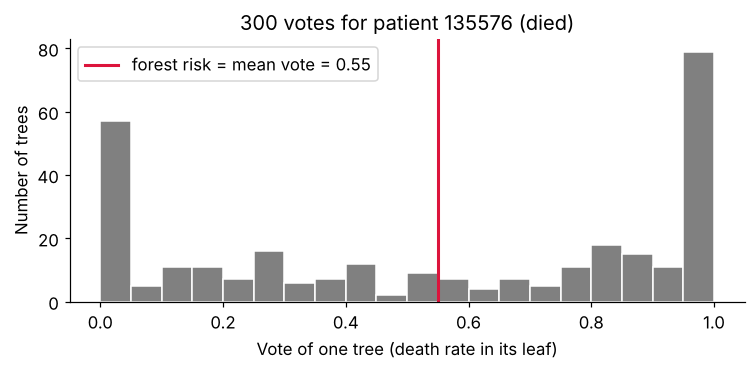

,depth,question_answered,patient_value,distinct_training_stays_in_node,bootstrap_weight_in_node,death_rate_in_node
0,0,SOFA > 13.50,17.0,1543,2400.0,0.141
1,1,GCS_last <= 8.50,8.0,72,120.0,0.508
2,2,Creatinine_first > 1.70,6.5,43,73.0,0.658
3,3,DiasABP_highest > 80.50,94.0,26,49.0,0.796
4,4,LEAF: this is the tree's vote,NaN,8,10.0,0.300


Leaf death rate = tree 0 vote: 0.300 vs 0.300


In [7]:
run = start_run("04-inside-the-forest", "transparency", config={**RF_PARAMS}, tags=["transparency", "random_forest"])

# Vote of every tree for every validation patient: shape (n_trees, n_patients)
X_val_np = X_val_t.to_numpy()
tree_probs = np.stack([t.predict_proba(X_val_np)[:, 1] for t in rf.estimators_])
max_gap = float(np.abs(tree_probs.mean(axis=0) - p_val_rf).max())
print(f"Forest risk = mean of tree votes? Largest difference over {tree_probs.shape[1]} patients: {max_gap:.1e}")

# --- 7.1 One patient: the validation patient who died and on whom the trees disagree most ---
tree_sd = tree_probs.std(axis=0)
np.testing.assert_allclose(tree_probs.mean(axis=0), p_val_rf, atol=1e-12, rtol=0)
deaths = np.where(y_val.values == 1)[0]
focus = int(deaths[np.argmax(tree_sd[deaths])])
focus_id = int(ICU.loc[idx_val[focus], ID_COL])

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(tree_probs[:, focus], bins=np.linspace(0, 1, 21), color="grey", edgecolor="white")
ax.axvline(p_val_rf[focus], color="crimson", lw=2, label=f"forest risk = mean vote = {p_val_rf[focus]:.2f}")
ax.set_xlabel("Vote of one tree (death rate in its leaf)"); ax.set_ylabel("Number of trees")
ax.set_title(f"300 votes for patient {focus_id} (died)"); ax.legend()
log_fig("votes_focus_patient", fig)

# Full path of this patient through tree number 0
tree0, t = rf.estimators_[0], rf.estimators_[0].tree_
x = X_val_np[[focus]]
rows = []
for depth, node in enumerate(tree0.decision_path(x).indices):
    rate = float(t.value[node, 0, 1] / t.value[node, 0].sum())
    if t.children_left[node] == -1:
        rule, value = "LEAF: this is the tree's vote", np.nan
    else:
        f, thr = t.feature[node], t.threshold[node]
        value = float(x[0, f])
        rule = f"{feat_names[f]} {'<=' if value <= thr else '>'} {thr:.2f}"
    rows.append({"depth": depth, "question_answered": rule, "patient_value": value,
                 "distinct_training_stays_in_node": int(t.n_node_samples[node]),
                 "bootstrap_weight_in_node": float(t.weighted_n_node_samples[node]), "death_rate_in_node": round(rate, 3)})
path_df = pd.DataFrame(rows)
display(path_df)
print(f"Leaf death rate = tree 0 vote: {rows[-1]['death_rate_in_node']:.3f} vs {tree_probs[0, focus]:.3f}")
wandb.log({"decision_path_tree0": wandb.Table(dataframe=path_df.astype({"patient_value": float}))})

## 7.2 Compare individual trees with the forest

Depth counts the longest sequence of questions; leaves count the endpoints. Compare each tree's validation AUROC with the forest's score

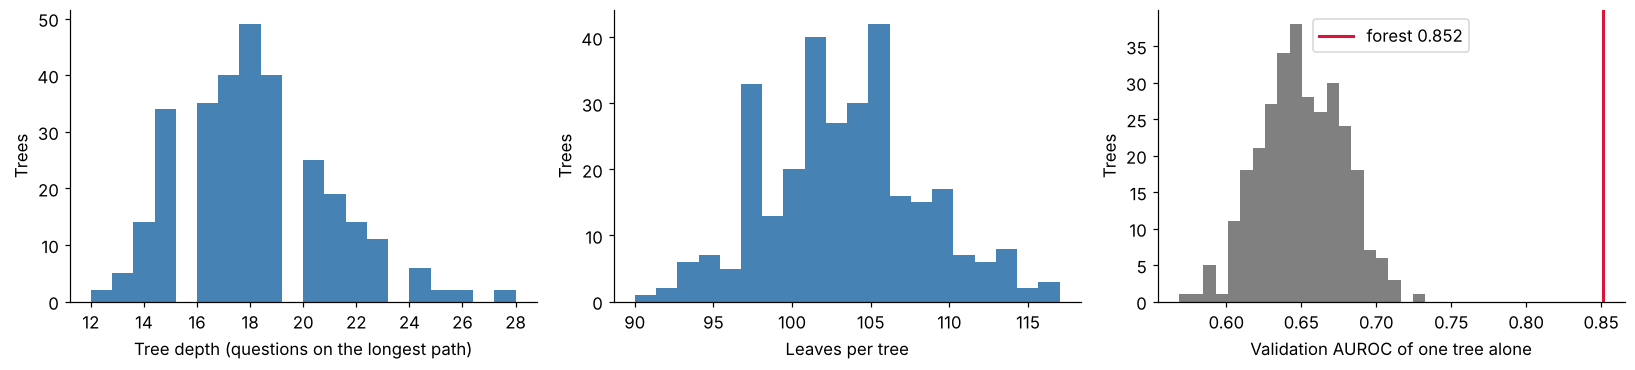

Mean single-tree AUROC 0.650 vs forest AUROC 0.852


In [8]:
anat = pd.DataFrame({
    "tree": range(len(rf.estimators_)),
    "depth": [e.get_depth() for e in rf.estimators_],
    "leaves": [e.get_n_leaves() for e in rf.estimators_],
    "val_auc_single_tree": [roc_auc_score(y_val, tp) for tp in tree_probs],
})
forest_auc = results["random_forest"]["val_auc"]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
axes[0].hist(anat["depth"], bins=20, color="steelblue"); axes[0].set_xlabel("Tree depth (questions on the longest path)")
axes[1].hist(anat["leaves"], bins=20, color="steelblue"); axes[1].set_xlabel("Leaves per tree")
axes[2].hist(anat["val_auc_single_tree"], bins=20, color="grey")
axes[2].axvline(forest_auc, color="crimson", lw=2, label=f"forest {forest_auc:.3f}"); axes[2].legend()
axes[2].set_xlabel("Validation AUROC of one tree alone")
for a in axes: a.set_ylabel("Trees")
log_fig("forest_anatomy", fig)
wandb.log({"forest_anatomy_table": wandb.Table(dataframe=anat), "mean_tree_depth": anat["depth"].mean(),
           "mean_leaves": anat["leaves"].mean(), "mean_single_tree_auc": anat["val_auc_single_tree"].mean()})
print(f"Mean single-tree AUROC {anat['val_auc_single_tree'].mean():.3f} vs forest AUROC {forest_auc:.3f}")

## 7.3 Add trees and inspect the internal check

Average the first 1, 2, ..., 300 trees from this fitted forest. The order is fixed, so this curve is one illustration of averaging, not a separate tuning experiment

AUPRC with 1, 10, 50, 300 trees: 0.276, 0.451, 0.485, 0.488
OOB AUPRC on training patients 0.481 vs validation AUPRC 0.488


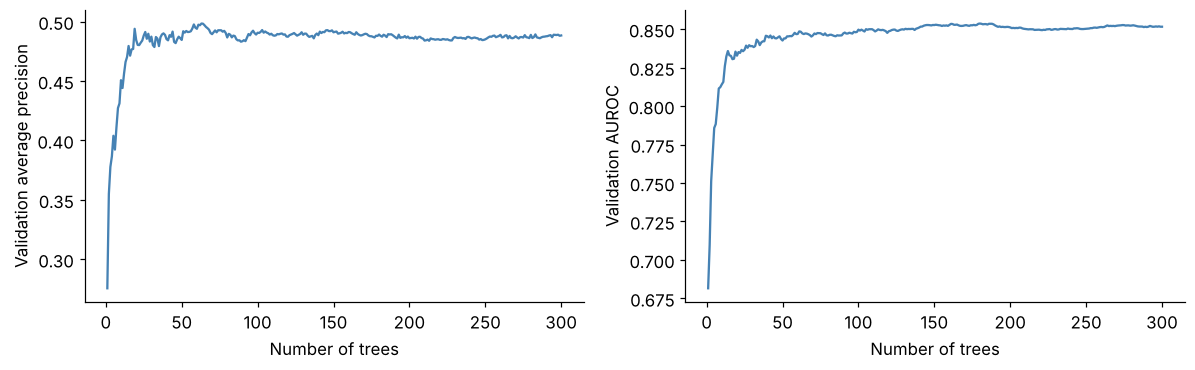

In [9]:
k = np.arange(1, len(rf.estimators_) + 1)
cum = np.cumsum(tree_probs, axis=0) / k[:, None]           # forest of the first k trees
pr_by_k = [average_precision_score(y_val, c) for c in cum]
auc_by_k = [roc_auc_score(y_val, c) for c in cum]
wandb.log({"performance_vs_n_trees": wandb.plot.line_series(
    xs=k.tolist(), ys=[pr_by_k, auc_by_k], keys=["val AUPRC", "val AUROC"],
    title="Validation performance of a forest made of the first k trees", xname="number of trees")})

oob_p = rf.oob_decision_function_[:, 1]
ok = np.isfinite(oob_p) & (rf.oob_decision_function_.sum(axis=1) > 0)
oob_pr = average_precision_score(y_train.iloc[np.flatnonzero(ok)], oob_p[ok])
wandb.log({"oob_pr": oob_pr})
print(f"AUPRC with 1, 10, 50, 300 trees: {pr_by_k[0]:.3f}, {pr_by_k[9]:.3f}, {pr_by_k[49]:.3f}, {pr_by_k[-1]:.3f}")
print(f"OOB AUPRC on training patients {oob_pr:.3f} vs validation AUPRC {results['random_forest']['val_pr']:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(k, pr_by_k, color="steelblue")
axes[1].plot(k, auc_by_k, color="steelblue")
for ax, label in zip(axes, ["Validation average precision", "Validation AUROC"]):
    ax.set(xlabel="Number of trees", ylabel=label)
log_fig("performance_vs_trees_notebook", fig)

## 7.4 Inspect disagreement between trees

Plot each validation patient's mean risk against the SD of tree probabilities. The boundary explains why the possible spread depends on the mean risk

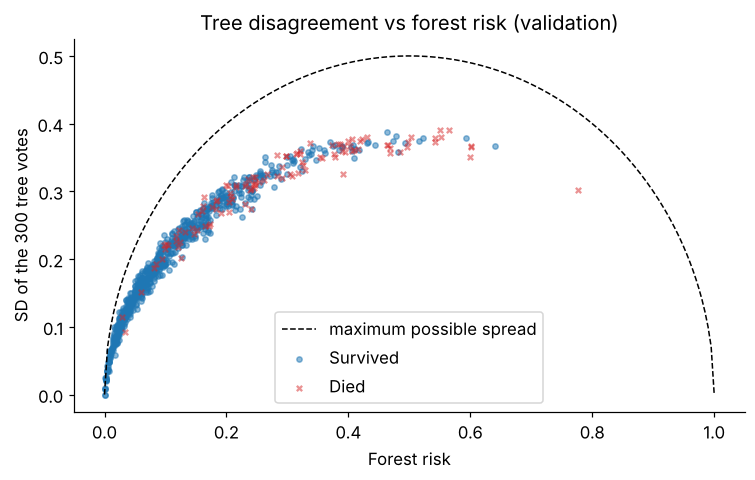

In [10]:
# Show raw tree spread. This is a description of the ensemble, not an uncertainty interval
fig, ax = plt.subplots(figsize=(7, 4.5))
grid = np.linspace(0, 1, 200)
ax.plot(grid, np.sqrt(grid * (1 - grid)), "k--", lw=1, label="maximum possible spread")
for lab, col, name in [(0, "tab:blue", "Survived"), (1, "tab:red", "Died")]:
    m = y_val.values == lab
    ax.scatter(p_val_rf[m], tree_sd[m], s=12, alpha=0.5, color=col,
               marker="o" if lab == 0 else "x", label=name)
ax.set_xlabel("Forest risk"); ax.set_ylabel("SD of the 300 tree votes"); ax.legend()
ax.set_title("Tree disagreement vs forest risk (validation)")
log_fig("tree_disagreement", fig)
disagree_df = pd.DataFrame({"recordid": ICU.loc[idx_val, ID_COL].values, "y_true": y_val.values,
                            "forest_risk": p_val_rf, "tree_sd": tree_sd})
wandb.log({"tree_disagreement_val": wandb.Table(dataframe=disagree_df)})
run.finish()

### Read the result

- Check that the largest averaging gap is close to zero, then follow tree 0's questions to its leaf probability
- Compare the individual-tree scores with the forest score. This shows what averaging achieved on these validation patients
- Find where the tree-count curve changes little. A plateau suggests limited benefit from adding more trees here
- Compare OOB and validation scores as two checks on different patients; close values do not make them interchangeable
- Inspect `tree_sd`. The dashed curve is the largest possible SD for votes between 0 and 1 at that mean risk, √[p(1−p)]

Tree spread can be larger near risk 0.5. It describes disagreement within this fitted forest, not a confidence interval or a guarantee about a patient's outcome

> Trace the tree probabilities and their average to understand how the forest calculates risk

# 8. Explain the model and check the explanation

| Section | Question | Check |
|---|---|---|
| 8.1 SHAP | Which recorded inputs contribute to this prediction? | Contributions plus a reference value recover the prediction |
| 8.2 Response curves | How does the model respond when one input changes? | Compare the average with individual curves |
| 8.3 Optional surrogate | Can a small tree imitate this forest? | Compare its predictions with the forest on validation patients |
| 8.4 Shuffled outcomes | Does a feature ranking guarantee useful prediction? | Check a forest trained without the original input-outcome link |

These tools describe model behaviour. They do not identify treatments or establish causes

## 8.1 SHAP: contributions to a prediction

SHAP assigns a contribution to each input. A positive value raises the prediction from its reference value; a negative value lowers it. A contribution of +0.05 adds 5 percentage points to the model's predicted probability

The sum check verifies the arithmetic, not the clinical truth of the explanation. This notebook uses the tree-path-dependent method, whose reference comes from the model's stored training paths. It is not simply the observed training death rate

Feature names include the Glasgow Coma Scale (GCS), a measure of responsiveness, and blood urea nitrogen (BUN), a kidney-related blood test. `last`, `highest` and `lowest` identify summaries within the first 48 h

Method: [SHAP TreeExplainer](https://shap.readthedocs.io/en/latest/generated/shap.TreeExplainer.html)

SHAP reference value (tree-path background): 0.139
Additivity check, largest gap over 500 patients: 3.3e-14


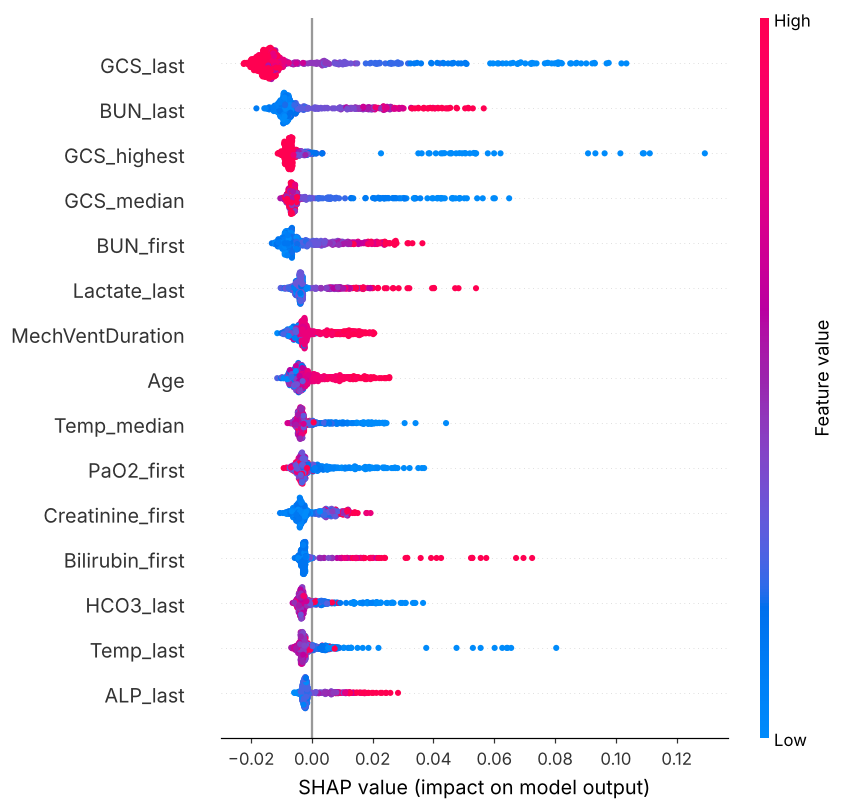

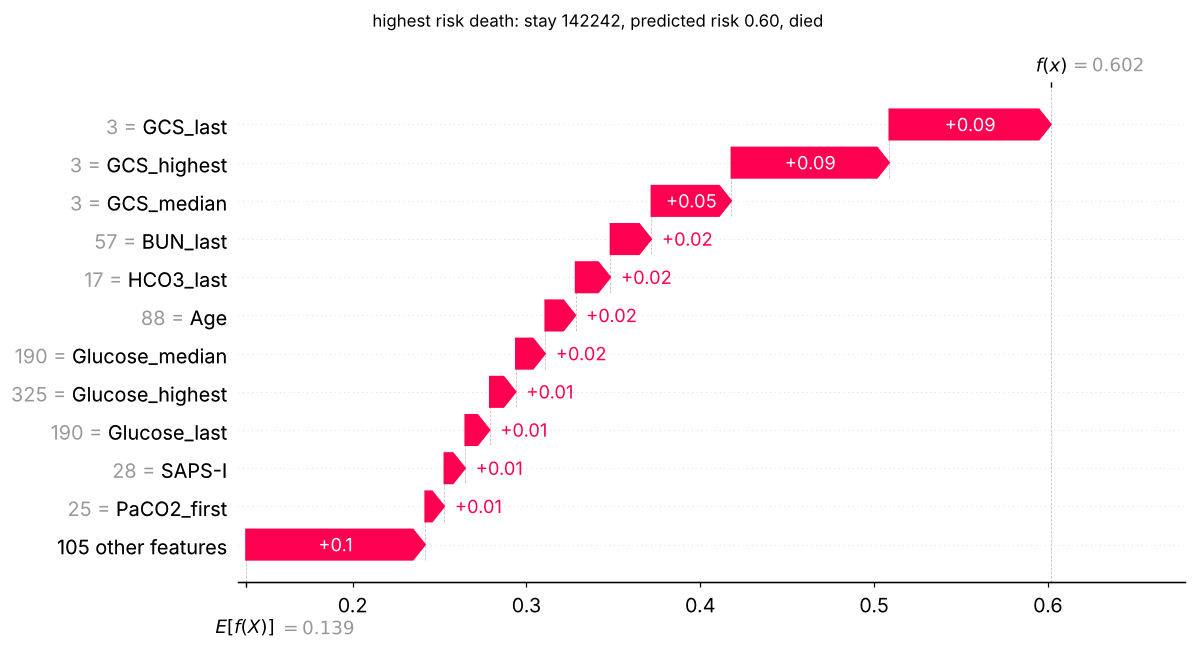

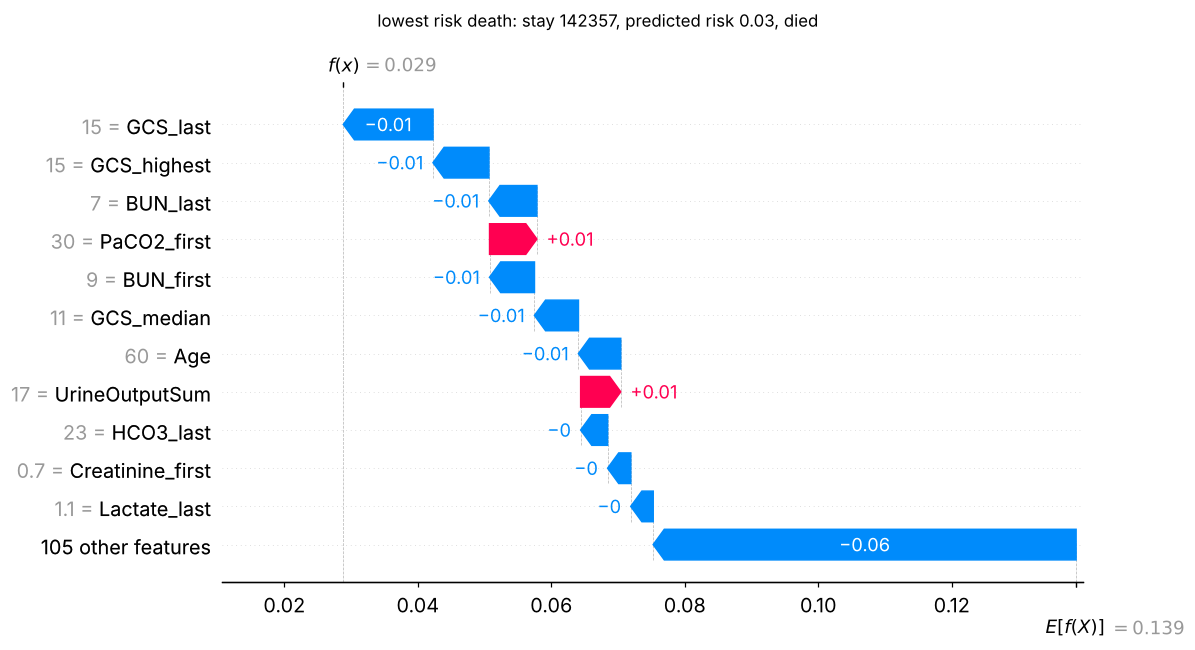

Top 3 features by mean |SHAP|: ['GCS_last', 'BUN_last', 'GCS_highest']


The largest average absolute contributions in these **500** validation stays are `GCS_last`, `BUN_last`, `GCS_highest`. The largest contribution-sum gap is **3.3e-14**; the arithmetic check passes. This verifies the decomposition of predictions, not a biological explanation.

In [11]:
run = start_run("05-explanations", "interpretability", config={"shap_sample_size": 500, "shap_method": "tree_path_dependent", **RF_PARAMS},
                tags=["interpretability", "random_forest"])

shap_X = X_val_t.sample(n=min(500, len(X_val_t)), random_state=SEED)
sv, base_value = rf_shap(rf, shap_X)
p_shap = rf.predict_proba(shap_X)[:, 1]

# Additivity check: SHAP reference + sum of the 116 SHAP values = this patient's predicted risk
add_gap = float(np.abs(base_value + sv.sum(axis=1) - p_shap).max())
print(f"SHAP reference value (tree-path background): {base_value:.3f}")
print(f"Additivity check, largest gap over {len(p_shap)} patients: {add_gap:.1e}")
np.testing.assert_allclose(base_value + sv.sum(axis=1), p_shap, atol=1e-7, rtol=0)
wandb.log({"shap_base_value": base_value, "shap_additivity_max_gap": add_gap})

# Global view
shap.summary_plot(sv, shap_X, show=False, max_display=15, rng=np.random.default_rng(SEED))
log_fig("shap_summary_plot", plt.gcf())
shap_df = pd.DataFrame({"feature": feat_names, "mean_abs_shap": np.abs(sv).mean(axis=0)}).sort_values("mean_abs_shap", ascending=False)
log_top_bar(shap_df, "feature", "mean_abs_shap", "rf_shap_importance_chart", "RF mean |SHAP| (top 15)")

# Local view: per-patient table with the 3 strongest drivers and tree disagreement from section 7
pos = idx_val.get_indexer(shap_X.index)
top3 = np.argsort(-np.abs(sv), axis=1)[:, :3]
y_s = y_val.loc[shap_X.index].values
expl_df = pd.DataFrame({
    "recordid": ICU.loc[shap_X.index, ID_COL].values, "y_true": y_s, "forest_risk": p_shap,
    "tree_sd": tree_sd[pos],
    "top_3_drivers": [", ".join(f"{feat_names[j]} ({sv[r, j]:+.3f})" for j in top3[r]) for r in range(len(sv))],
})
wandb.log({"patient_explanations_val": wandb.Table(dataframe=expl_df)})

# Waterfalls: the death ranked highest and the death ranked lowest by the forest
d_idx = np.where(y_s == 1)[0]
for label, i in {"highest_risk_death": d_idx[np.argmax(p_shap[d_idx])], "lowest_risk_death": d_idx[np.argmin(p_shap[d_idx])]}.items():
    shap.plots.waterfall(shap.Explanation(values=sv[i], base_values=base_value, data=shap_X.iloc[i].values,
                                          feature_names=feat_names), max_display=12, show=False)
    fig = plt.gcf(); fig.set_size_inches(11, 6)
    fig.suptitle(f"{label.replace(chr(95), chr(32))}: stay {expl_df.recordid.iloc[i]}, predicted risk {p_shap[i]:.2f}, died", fontsize=11)
    fig.tight_layout()
    log_fig(f"shap_waterfall_{label}", fig)

TOP_SHAP = shap_df["feature"].head(3).tolist()
print("Top 3 features by mean |SHAP|:", TOP_SHAP)
display(Markdown(f"The largest average absolute contributions in these **{len(shap_X)}** validation stays are "
                 + ", ".join(f"`{f}`" for f in TOP_SHAP)
                 + f". The largest contribution-sum gap is **{add_gap:.1e}**; the arithmetic check passes. "
                 + "This verifies the decomposition of predictions, not a biological explanation."))
run.finish()

### Read the result

- Check that the contribution sum matches each prediction within the printed numerical tolerance
- In the summary plot, each dot is one patient. Colour shows the input value; horizontal position shows its contribution
- Follow the waterfall for the lowest-risk death. Which inputs pulled the prediction down from the reference?
- Compare it with the highest-risk death. These are deliberately selected examples, not typical patients or threshold-defined errors

Related inputs can share predictive information. Their assigned contributions depend on the explanation method. Notebook 03 section 6.1 examines related inputs together

> Use SHAP to explain a model prediction, then check its arithmetic and assumptions

## 8.2 Response curves: one guided example

A partial dependence plot (PDP) averages the model's predicted risk as one feature changes and the others stay as recorded. Individual conditional expectation (ICE) curves show that response for separate patients

This example varies only the input with the largest average SHAP contribution in section 8.1, on 100 validation patients

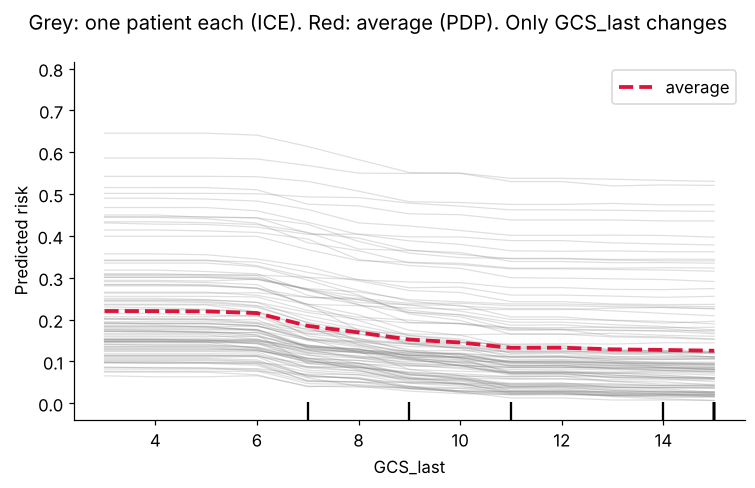

In [12]:
run = start_run("05b-response-curves", "interpretability", config={"pdp_feature": TOP_SHAP[0], "ice_patients": 100},
                tags=["interpretability"])
fig, ax = plt.subplots(figsize=(7, 4.5))
PartialDependenceDisplay.from_estimator(
    rf, X_val_t, features=[TOP_SHAP[0]], kind="both", subsample=100, random_state=SEED, grid_resolution=30, ax=ax,
    ice_lines_kw={"color": "grey", "alpha": 0.25, "lw": 0.8}, pd_line_kw={"color": "crimson", "lw": 2.5})
plt.gcf().axes[-1].set_ylabel("Predicted risk")
plt.gcf().suptitle(f"Grey: one patient each (ICE). Red: average (PDP). Only {TOP_SHAP[0]} changes")
log_fig("pdp_ice_top_feature", plt.gcf())
run.finish()

### Read the curves

- A flat average curve means little average response over that range; individual responses can still differ
- Curves with different shapes suggest the model combines this input with others
- The small marks on the horizontal axis show common individual feature values. They do not establish that every generated combination is realistic

Changing one summary while holding related summaries fixed can produce impossible combinations, such as a last value above the recorded maximum. These are model-response curves, not treatment effects. See the [scikit-learn guidance](https://scikit-learn.org/stable/modules/partial_dependence.html)

> Check individual responses and realistic input combinations before interpreting an average curve

## 8.3 Optional: how much can a small tree imitate?

A **surrogate** is a simpler model trained to imitate another model's predictions. Here the target is the fitted forest's probability on training inputs, not the patient's outcome. Using OOB probabilities would imitate different subsets of trees for different patients, rather than this one fitted forest

Fit trees with depths 1 to 5 and compare their probabilities with the forest on validation patients. **Fidelity R²** measures agreement relative to a constant validation-mean predictor: 1 is perfect, 0 matches that reference, and negative values are worse

A surrogate is an approximate explanation of the baseline forest. It is not the final refitted model or evidence that a simpler clinical model is adequate

In [13]:
if RUN_SURROGATE:
    run = start_run("06-global-surrogate", "interpretability", config={"surrogate_min_samples_leaf": 30},
                    tags=["interpretability", "surrogate"])
    forest_training_risk = rf.predict_proba(X_train_t)[:, 1]
    rows = []
    for depth in range(1, 6):
        sur = DecisionTreeRegressor(max_depth=depth, min_samples_leaf=30, random_state=SEED).fit(X_train_t, forest_training_risk)
        s_val = sur.predict(X_val_t)
        rows.append({"depth": depth, "leaves": sur.get_n_leaves(), "fidelity_r2_val": r2_score(p_val_rf, s_val),
                     "mean_abs_risk_gap_val": np.mean(np.abs(p_val_rf - s_val))})
    sur_df = pd.DataFrame(rows)
    display(sur_df.round(3))
    wandb.log({"surrogate_fidelity": wandb.plot.line_series(
        xs=sur_df["depth"].tolist(), ys=[sur_df["fidelity_r2_val"].tolist()],
        keys=["fidelity R²"], title="Surrogate fidelity vs depth", xname="max depth"),
        "surrogate_table": wandb.Table(dataframe=sur_df)})
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
    axes[0].plot(sur_df.depth, sur_df.fidelity_r2_val, marker="o", color="steelblue")
    axes[1].plot(sur_df.depth, sur_df.mean_abs_risk_gap_val * 100, marker="o", color="steelblue")
    axes[0].set(xlabel="Maximum depth", ylabel="Fidelity R²", title="Agreement with the forest")
    axes[1].set(xlabel="Maximum depth", ylabel="Mean absolute gap (percentage points)", title="Probability gap from the forest")
    log_fig("surrogate_fidelity_notebook", fig)

    SURROGATE_DEPTH = 3
    sur3 = DecisionTreeRegressor(max_depth=SURROGATE_DEPTH, min_samples_leaf=30, random_state=SEED).fit(X_train_t, forest_training_risk)
    SURROGATE_R2 = float(sur_df.loc[sur_df.depth == SURROGATE_DEPTH, "fidelity_r2_val"].iloc[0])
    fig, ax = plt.subplots(figsize=(15, 6))
    plot_tree(sur3, feature_names=feat_names, filled=True, rounded=True, fontsize=9, precision=2, ax=ax)
    ax.set_title(f"Depth-{SURROGATE_DEPTH} surrogate of the forest, fidelity R² = {SURROGATE_R2:.2f} (leaf value = mean forest risk)")
    log_fig("surrogate_tree_depth3", fig)
    run.finish()
else:
    print("Optional surrogate skipped")

Optional surrogate skipped


### Read the optional surrogate

- Check depth 3's fidelity and mean absolute probability gap. A gap of 0.03 means 3 percentage points on average
- Depth 3 allows up to three questions on any patient path and up to seven split nodes across the whole tree
- Compare the first splits with the top SHAP inputs. Different summaries need not give the same ranking

Whatever the fidelity, agreement is only with this forest. Any unexplained variation need not come from interactions, and high fidelity does not establish clinical accuracy

> Use the small tree as an approximate explanation and report how closely it matches the forest

## 8.4 Sanity check: a ranking is not evidence of useful prediction

Shuffle the training outcomes, then fit the same forest. This removes the original input-outcome pairing. The validation outcomes stay unchanged

The forest can still split noisy training data and produce **impurity importance**, its built-in relative feature ranking. Those values normally sum to one even when validation prediction is poor. A nonzero ranking alone therefore does not establish useful signal

One shuffled run is an illustration, not a formal test. Its validation scores need not equal chance exactly. It also cannot prove why a particular feature ranks highly. Controlled evidence of bias toward features with many distinct values is given in the [scikit-learn example](https://scikit-learn.org/stable/auto_examples/inspection/plot_permutation_importance.html)

A small check closes the loop: shuffle each of the shuffled model's top 10 features in the validation data and measure the drop in average precision. A feature the model truly uses for prediction causes a clear drop; notebook 03 section 6.1 covers permutation importance in full

,AUROC,average precision
real labels,0.852,0.488
shuffled training labels,0.557,0.152
chance reference,0.500,0.139


,feature,impurity_real,impurity_shuffled,permutation_drop_real,permutation_drop_shuffled
2,Age,0.0153,0.0194,0.0100,-0.0038
22,Glucose_last,0.0127,0.0167,0.0012,0.0012
98,HCT_last,0.0083,0.0162,0.0031,0.0007
85,WBC_first,0.0101,0.0161,-0.0001,0.0010
81,Platelets_first,0.0113,0.0158,0.0015,0.0007
74,HCT_first,0.0074,0.0156,-0.0009,0.0001
5,Weight,0.0120,0.0154,0.0007,0.0022
23,HR_last,0.0107,0.0152,0.0057,0.0023
109,WBC_last,0.0179,0.0140,0.0034,-0.0003
68,BUN_first,0.0204,0.0138,-0.0010,-0.0036


Sum of shuffled-model impurity importances: 1.000


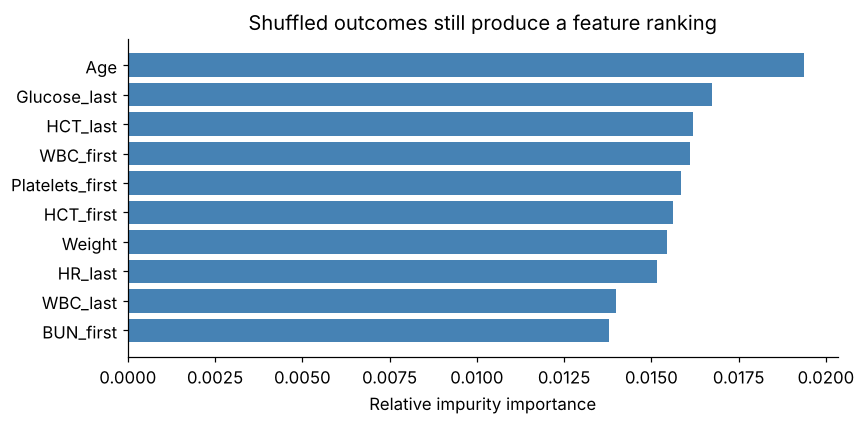

The shuffled-outcome forest has validation AUROC **0.557** and average precision **0.152**, compared with chance references of **0.500** and **0.139**. Its importances still sum to **1.000**. On validation, shuffling one of its top 10 features changes average precision by at most **0.004**. A complete-looking ranking can accompany poor prediction.

In [14]:
run = start_run("07-explanation-sanity-check", "sanity-check", config={**RF_PARAMS, "label_shuffle_seed": SEED},
                tags=["interpretability", "sanity-check"])
rng = np.random.default_rng(SEED)
y_shuffled = pd.Series(rng.permutation(y_train.values), index=y_train.index)
rf_null = RandomForestClassifier(**RF_PARAMS, random_state=SEED, n_jobs=-1).fit(X_train_t, y_shuffled)
null_scores = score(y_val, rf_null.predict_proba(X_val_t)[:, 1])
null_comparison = pd.DataFrame({
    "real labels": {"AUROC": forest_auc, "average precision": results["random_forest"]["val_pr"]},
    "shuffled training labels": {"AUROC": null_scores["auc"], "average precision": null_scores["pr"]},
    "chance reference": {"AUROC": 0.5, "average precision": y_val.mean()},
}).T
display(null_comparison.round(3))
check_df = pd.DataFrame({"feature": feat_names, "impurity_real": rf.feature_importances_,
                         "impurity_shuffled": rf_null.feature_importances_})
# Validation permutation check on the shuffled model's top 10 impurity features (5 shuffles each)
def perm_drop(model, feature, repeats=5):
    """Mean drop in validation average precision when one feature is shuffled"""
    base = average_precision_score(y_val, model.predict_proba(X_val_t)[:, 1])
    drops = []
    for r in range(repeats):
        Xp = X_val_t.copy()
        Xp[feature] = np.random.default_rng(SEED + r).permutation(Xp[feature].to_numpy())
        drops.append(base - average_precision_score(y_val, model.predict_proba(Xp)[:, 1]))
    return float(np.mean(drops))

top10 = check_df.nlargest(10, "impurity_shuffled").copy()
top10["permutation_drop_real"] = [perm_drop(rf, f) for f in top10.feature]
top10["permutation_drop_shuffled"] = [perm_drop(rf_null, f) for f in top10.feature]
display(top10.round(4))
print(f"Sum of shuffled-model impurity importances: {rf_null.feature_importances_.sum():.3f}")
fig, ax = plt.subplots(figsize=(8, 4))
top = check_df.nlargest(10, "impurity_shuffled").sort_values("impurity_shuffled")
ax.barh(top.feature, top.impurity_shuffled, color="steelblue")
ax.set(xlabel="Relative impurity importance", title="Shuffled outcomes still produce a feature ranking")
log_fig("sanity_check_importance", fig)
wandb.log({"sanity_check_table": wandb.Table(dataframe=check_df), "sanity_check_top10": wandb.Table(dataframe=top10),
           "null_val_auc": null_scores["auc"], "null_val_pr": null_scores["pr"]})
display(Markdown(f"The shuffled-outcome forest has validation AUROC **{null_scores['auc']:.3f}** "
                 f"and average precision **{null_scores['pr']:.3f}**, compared with chance references "
                 f"of **0.500** and **{y_val.mean():.3f}**. Its importances still sum to **1.000**. "
                 f"On validation, shuffling one of its top 10 features changes average precision by at most "
                 f"**{top10.permutation_drop_shuffled.abs().max():.3f}**. A complete-looking ranking can accompany poor prediction."))
run.finish()

### Read the result

- Compare the real and shuffled models with the chance references
- Check the shuffled model's feature ranking. Does a sorted list by itself show predictive value?
- Compare the two permutation columns. Drops near zero mean the model gains little from that feature on unseen patients. Small values, positive or negative, are expected from noise
- Compare its top features with the baseline ranking, without treating overlap as proof of bias

> Check held-out prediction before treating a feature ranking as useful evidence

# 9. Tune the forest and track the trade-offs

A W&B **sweep** tries different model settings and selects by validation average precision. This Bayesian search uses earlier results to guide later trials; ten trials are a small demonstration, not an exhaustive search

- `train_pr` and `val_pr` compare ranking on training and validation patients
- `overfit_gap_pr` is their difference; a large gap suggests poor transfer from training to validation
- `mean_tree_depth` and `mean_leaves` describe model size
- `fit_seconds` records training time on this computer
- `oob_pr` and `val_ece` provide additional checks without repeating their analyses

Class weights stay at their default so the sweep changes only four settings. No claim about whether balanced weights would help is tested here

In [15]:
def train_rf_sweep():
    run = start_run(None, "sweep-agent", tags=["sweep"])
    cfg = wandb.config
    from time import perf_counter
    started = perf_counter()
    model = RandomForestClassifier(
        n_estimators=cfg.n_estimators, max_depth=None if cfg.max_depth == 0 else cfg.max_depth,
        max_features=cfg.max_features, min_samples_leaf=cfg.min_samples_leaf,
        oob_score=True, random_state=SEED, n_jobs=-1).fit(X_train_t, y_train)
    fit_seconds = perf_counter() - started
    sc = score(y_val, model.predict_proba(X_val_t)[:, 1])
    oob = model.oob_decision_function_[:, 1]
    m = np.isfinite(oob) & (model.oob_decision_function_.sum(axis=1) > 0)
    train_pr = average_precision_score(y_train, model.predict_proba(X_train_t)[:, 1])
    wandb.log({**{f"val_{k}": v for k, v in sc.items()},
               "fit_seconds": fit_seconds, "train_pr": train_pr, "overfit_gap_pr": train_pr - sc["pr"],
               "oob_pr": average_precision_score(y_train.iloc[np.flatnonzero(m)], oob[m]),
               "mean_tree_depth": float(np.mean([e.get_depth() for e in model.estimators_])),
               "mean_leaves": float(np.mean([e.get_n_leaves() for e in model.estimators_]))})
    run.finish()

sweep_config = {
    "name": "rf_transparency_v2",
    "method": "bayes",
    "metric": {"name": "val_pr", "goal": "maximize"},
    "parameters": {
        "n_estimators": {"values": [100, 200, 300, 500]},
        "max_depth": {"values": [0, 4, 8, 12, 16]},   # 0 means no limit
        "max_features": {"values": ["sqrt", "log2"]},
        "min_samples_leaf": {"values": [1, 3, 5, 10, 20]},
    },
}
SWEEP_COUNT = 10  # runtime depends on the computer and selected settings

if WANDB_MODE != "online":
    sweep_id = None
    print("Sweeps need WANDB_MODE='online'. Skipped: section 10 uses the baseline settings")
else:
    sweep_id = wandb.sweep(sweep_config, project=WB_PROJECT)
    wandb.agent(sweep_id, function=train_rf_sweep, count=SWEEP_COUNT)
    print(f"Sweep {sweep_id} complete")

Sweeps need WANDB_MODE='online'. Skipped: section 10 uses the baseline settings


### Read the online sweep

- Add `val_pr`, `overfit_gap_pr`, `mean_tree_depth` and `fit_seconds` to Parallel Coordinates
- Compare a high-scoring configuration with a simpler one. How much validation gain accompanies the extra complexity?
- Check whether OOB and validation rank configurations similarly; agreement here does not establish that either can replace an independent final test
- Treat Parameter Importance as exploratory with only ten trials

> Track validation gain alongside training time, model size and the training-validation gap

# 10. Save the complete model and evaluate test once

1. Read completed sweep runs through the W&B application programming interface (API), or use baseline settings offline
2. Retain the baseline if the best sweep score is lower. Any selected validation gain is optimistic because the same validation set guided the search
3. Fit preprocessing and the chosen forest on train plus validation, then evaluate the fixed test set once
4. Save the **complete pipeline**, including preprocessing, its settings and library versions
5. Reload the file and rebuild from logged settings. Compare predictions within a numerical tolerance; do not use these checks to choose another model

The Registry link is optional. Set `REGISTRY_TARGET` to an existing Registry collection path with the exact name and case used in the account. An empty path skips this step explicitly

In [16]:
# Select only completed, scored runs from this sweep. API failures stop here rather than silently selecting another model
best_run, rf_params = None, dict(RF_PARAMS)
baseline_pr = results["random_forest"]["val_pr"]
best_val_pr = baseline_pr
if sweep_id:
    api = WandbApi()
    sweep_path = f"{WB_ENTITY}/{WB_PROJECT}/{sweep_id}"
    completed = [r for r in api.sweep(sweep_path).runs
                 if r.state == "finished" and isinstance(r.summary.get("val_pr"), (int, float))
                 and np.isfinite(r.summary["val_pr"])]
    if not completed:
        raise RuntimeError("No completed sweep runs with a finite val_pr; inspect the sweep before final evaluation")
    candidate = max(completed, key=lambda r: r.summary["val_pr"])
    print(f"Best completed sweep val_pr: {candidate.summary['val_pr']:.3f}; baseline: {baseline_pr:.3f}")
    if candidate.summary["val_pr"] > baseline_pr:
        best_run = candidate
        c = best_run.config
        rf_params = {"n_estimators": int(c["n_estimators"]),
                     "max_depth": None if int(c["max_depth"]) == 0 else int(c["max_depth"]),
                     "max_features": c["max_features"], "min_samples_leaf": int(c["min_samples_leaf"])}
        best_val_pr = float(candidate.summary["val_pr"])

gain = best_val_pr - baseline_pr
print(f"Selected validation gain: {gain:+.3f}; baseline split SD: {SPLIT_SD_PR:.3f} (context only)")
print("No significance verdict: five overlapping splits and a selected validation maximum cannot establish a tuning benefit")

final_rf_config = RandomForestClassifier(**rf_params, random_state=SEED, n_jobs=-1).get_params()
run = start_run("08-final-model", "final_eval", config={
    "selected_rf_params": final_rf_config, "selected_val_pr": best_val_pr,
    "tuning_gain_val_pr": gain, "baseline_split_sd_val_pr": SPLIT_SD_PR,
    "source_sweep": sweep_id, "source_run_id": best_run.id if best_run else None,
    "preprocessing": "source -1 codes converted to missing before training medians; most frequent categorical values; one-hot encoding",
}, tags=["final"])

idx_trval = idx_train.append(idx_val)
final_pipeline = Pipeline([("preprocess", make_preprocessor()), ("forest", RandomForestClassifier(**final_rf_config))])
final_pipeline.fit(X.loc[idx_trval], y.loc[idx_trval])
y_test_prob = final_pipeline.predict_proba(X.loc[idx_test])[:, 1]
test_metrics = {f"test_{k}": v for k, v in score(y.loc[idx_test], y_test_prob).items()}
wandb.log(test_metrics)
log_curves(y.loc[idx_test], y_test_prob, "test_final")
print({k: round(v, 3) for k, v in test_metrics.items()})
print(f"Test stays: {len(idx_test)}; deaths: {int(y.loc[idx_test].sum())}; PR reference: {y.loc[idx_test].mean():.3f}")

model_file = OUTPUT_DIR / "icu_rf_v2_pipeline.joblib"
joblib.dump(final_pipeline, model_file)
loaded = joblib.load(model_file)
gap_file = float(np.abs(loaded.predict_proba(X.loc[idx_test])[:, 1] - y_test_prob).max())
refit = Pipeline([("preprocess", make_preprocessor()),
                  ("forest", RandomForestClassifier(**dict(run.config["selected_rf_params"])))])
refit.fit(X.loc[idx_trval], y.loc[idx_trval])
gap_refit = float(np.abs(refit.predict_proba(X.loc[idx_test])[:, 1] - y_test_prob).max())
np.testing.assert_allclose(loaded.predict_proba(X.loc[idx_test])[:, 1], y_test_prob, atol=1e-9, rtol=0)
assert gap_refit < 1e-9, "Rebuilt predictions differ; check data, preprocessing, settings and versions"
wandb.log({"repro_saved_file_max_gap": gap_file, "repro_refit_max_gap": gap_refit,
           "repro_saved_file_ok": gap_file < 1e-9, "repro_refit_from_config_ok": gap_refit < 1e-9})
print(f"Reload max gap {gap_file:.1e}; rebuild max gap {gap_refit:.1e}; tolerance 1e-9")

settings_file = OUTPUT_DIR / "icu_rf_v2_settings.json"
settings_file.write_text(json.dumps(dict(run.config), indent=2), encoding="utf-8")
versions_file = OUTPUT_DIR / "requirements-run.txt"
versions_file.write_text("\n".join(f"{p}=={v}" for p, v in VERSIONS.items()) + "\n", encoding="utf-8")
model_at = wandb.Artifact("icu-rf-v2-pipeline", type="model",
    description="Teaching pipeline: predict hospital death after the first 48 h of an ICU stay",
    metadata={"forest_params": final_rf_config, **test_metrics, "trained_on": "train + validation",
              "split_seed": SEED, "environment": ENVIRONMENT, "input_versions": INPUT_REFS,
              "dataset_sha256": DATA_SHA256, "split_sha256": SPLIT_SHA256,
              "prediction_time": "after 48 h in ICU", "intended_use": "Teaching only",
              "known_limits": "Historical research cohort; excludes stays shorter than 48 h; no external or clinical validation",
              "selected_by": "validation average precision" if best_run else "baseline settings",
              "repro_saved_file_max_gap": gap_file, "repro_refit_max_gap": gap_refit})
for file in [model_file, settings_file, versions_file, Path("environment.yml")]:
    model_at.add_file(str(file))
logged_model = run.log_artifact(model_at, aliases=["teaching_candidate"])
if WANDB_MODE == "online" and REGISTRY_TARGET:
    logged_model.wait()
    run.link_artifact(logged_model, REGISTRY_TARGET, aliases=["staging"])
    print("Registry link requested:", REGISTRY_TARGET)
else:
    print("Registry skipped: online mode and an explicit collection path are required")
display(Markdown(f"On **{len(idx_test)}** held-out stays, including **{int(y.loc[idx_test].sum())}** deaths, "
                 f"the final pipeline has AUROC **{test_metrics['test_auc']:.3f}** and average precision "
                 f"**{test_metrics['test_pr']:.3f}**. Its Brier score is **{test_metrics['test_brier']:.3f}** "
                 f"and ECE is **{test_metrics['test_ece']:.3f}**. "
                 "These describe this historical test sample; clinical usefulness needs separate evidence."))
run.finish()

Selected validation gain: +0.000; baseline split SD: 0.044 (context only)
No significance verdict: five overlapping splits and a selected validation maximum cannot establish a tuning benefit


{'test_auc': 0.864, 'test_pr': 0.52, 'test_brier': 0.091, 'test_ece': 0.042}
Test stays: 800; deaths: 111; PR reference: 0.139


Reload max gap 1.1e-16; rebuild max gap 1.1e-16; tolerance 1e-9
Registry skipped: online mode and an explicit collection path are required


On **800** held-out stays, including **111** deaths, the final pipeline has AUROC **0.864** and average precision **0.520**. Its Brier score is **0.091** and ECE is **0.042**. These describe this historical test sample; clinical usefulness needs separate evidence.

### Read the result

- Report the printed test scores with their patient count and precision-recall reference
- Open `icu-rf-v2-pipeline` online. It contains preprocessing, the forest, settings and library versions
- Inspect lineage: raw data and split artifacts feed the final run, which produces the model artifact
- Check both prediction gaps against `1e-9`. Tiny differences can come from the order of floating-point additions
- If Registry linking was enabled, verify the `staging` alias in the selected collection

The rebuild check runs in this environment with these data. It does not promise identical results across library versions. Earlier SHAP and surrogate results describe the baseline forest, so they are not included as final-model explanations

> Save preprocessing with the model and verify that reloading and rebuilding preserve its predictions

W&B references: [sweep API source](https://github.com/wandb/wandb/blob/main/wandb/apis/public/sweeps.py), [artifact and Registry API source](https://github.com/wandb/wandb/blob/main/wandb/sdk/wandb_run.py)

# 11. Optional follow-up: write a short W&B Report

Use Reports > Create report. Keep the report to five pieces of evidence

- Intended use, prediction time, source cohort and exclusions
- Baseline scores and the paired development-split comparisons
- One tree path and one SHAP waterfall from the baseline forest
- Final test scores, complete pipeline artifact version and reproducibility gaps
- Limits and the next check needed before using these predictions elsewhere

Label every panel with its model and run. Optional curves and surrogate results belong to the baseline forest, not the final refit

Notebook 03 and RAI demonstrate calibration and policy checks on other models. Link them as methods to apply, not as completed validation of this pipeline

# 12. Key takeaways

- Record data versions, patient splits and settings so another person can trace each result
- Compare models on shared development splits and keep test patients outside exploration
- Follow tree probabilities and their average to explain how a forest calculates risk
- Check explanation arithmetic and predictive performance before interpreting a feature ranking
- Save the complete pipeline and verify its predictions after reloading and rebuilding